# E5 — Phase-decomposed context architecture (C2, gate G3)

**H4 / G3 (pre-registered).** A phase-decomposed agent raises the resolved rate by at
least 5 points over the tuned monolithic agent at equal wall-clock (same 6-min budget,
same task × seed pairs); falsified if the paired 95% CI of the gain includes 0.

**Agent** (`src/build_submission.py`, declarative YAML only):
`SequentialAgent[Localizer, Reproducer, LoopAgent×3[Editor, Verifier]]`. Every phase
uses `include_contents: none` (fresh context: previous phase's note + own tool calls) and
gets the issue plus structured hand-offs through session state (`output_key`). Prompts
share a byte-identical prefix. Same model, sampling, adapters and output-reserve fix as
the baseline (E1b arm B), so the difference isolates the architecture.

## 0 · Parameters

In [1]:
CONFIG_OVERRIDES: dict = {}

In [2]:
# Parameters
CONFIG_OVERRIDES = "{\"params.variant\": \"phase_v2_3\", \"params.subset\": \"dev40\", \"params.seeds\": [1], \"params.baseline_dir\": \"<repo>/experiments/E1b_context_fixes/runs/20260925T210110Z-31559935-5542/artifacts/swebox/arm_B\"}"


## 1 · Setup & provenance

In [3]:
from pathlib import Path

import polars as pl
from IPython.display import Markdown, display
from src.build_submission import build
from src.params import Params

from rbcore import RunContext, load_config, plotting, stats
from swebox import sandbox as sb
from swebox.analysis import load_results, load_steps
from swebox.evaluate import EvalSpec, evaluate
from swebox.submission import ServingTarget
from swebox.tasks import load_tasks, select
from swebox.tools import Budget

EXP_DIR = Path.cwd()
cfg = load_config(EXP_DIR / "config.yaml", Params, CONFIG_OVERRIDES)
P = cfg.params
plotting.use_style()
tasks = select(load_tasks(), P.subset)
task_ids = {t.instance_id for t in tasks}
limits = sb.Limits(cfg.sandbox.mem_gib or 8, cfg.sandbox.cpus or 4)
display(
    Markdown(
        f"config `{cfg.hash()}` · {P.variant} · {len(tasks)} tasks × seeds {P.seeds} "
        f"= **{len(tasks) * len(P.seeds)} sessions** · baseline: `{P.baseline_dir}`"
    )
)

<repo>/harness/src/swebox/agent_runner.py:44: UserWarning: [EXPERIMENTAL] EventsCompactionConfig: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  COMPACTION = EventsCompactionConfig(
<repo>/.venv/lib/python3.12/site-packages/google/adk/features/_feature_decorator.py:71: UserWarning: [EXPERIMENTAL] feature FeatureName.AGENT_CONFIG is enabled.
  check_feature_enabled()


config `7cd185036c00` · phase_v2_3 · 40 tasks × seeds [1] = **40 sessions** · baseline: `<repo>/experiments/E1b_context_fixes/runs/20260925T210110Z-31559935-5542/artifacts/swebox/arm_B`

## 2 · Preflight

In [4]:
import httpx

served = {
    m["id"]
    for m in httpx.get(f"{cfg.serving.base_url}/v1/models", timeout=5)
    .raise_for_status()
    .json()["data"]
}
assert "main_lora" in served, f"adapters not served: {served} (infra/vllm/serve_submission.sh)"
baseline = pl.DataFrame()
if P.baseline_dir:
    baseline = load_results(Path(P.baseline_dir)).filter(
        pl.col("instance_id").is_in(task_ids) & pl.col("seed").is_in(P.seeds)
    )
    display(Markdown(f"baseline rows: {baseline.height} / {len(task_ids) * len(P.seeds)}"))
sb.client().ping()

baseline rows: 40 / 40

True

## 3 · Open the run and build the submission
The generated submission is stored in the run's artifacts (exactly what was evaluated).

In [5]:
run = RunContext(cfg, exp_dir=EXP_DIR).start()  # closed in section 9 with run.finish()
out_root = Path(P.results_dir) if P.results_dir else run.artifacts / "swebox"
run.event("results_dir", path=str(out_root), resumed=P.results_dir is not None)
submission = build(P.variant, run.artifacts / "submission" / P.variant, P.output_reserve)
print(run.dir, submission)

2026-09-26T19:42:22.660563Z [warning  ] run.sandbox_not_eval_faithful  [rbcore.run] experiment=E5_context_architecture note='fine for development; headline numbers need profile=eval' profile=dev run_id=20260926T194221Z-7cd18503-d596


[codecarbon WARNING @ 19:42:23] Multiple instances of codecarbon are allowed to run at the same time.


<repo>/experiments/E5_context_architecture/runs/20260926T194221Z-7cd18503-d596 <repo>/experiments/E5_context_architecture/runs/20260926T194221Z-7cd18503-d596/artifacts/submission/phase_v2_3


## 4 · Run

In [6]:
spec = EvalSpec(
    submission=submission,
    limits=limits,
    budget=Budget(time_minutes=P.time_minutes),
    target=ServingTarget(api_base=f"{cfg.serving.base_url}/v1", served_model=cfg.serving.model),
    seeds=tuple(P.seeds),
    concurrency=P.concurrency,
    tag=P.variant,
)
with run.phase("variant", variant=P.variant):
    rows = await evaluate(tasks, spec, out_root / P.variant, run=run)
run.log_metrics({"resolved": sum(r["resolved"] for r in rows) / len(rows)})

<repo>/.venv/lib/python3.12/site-packages/google/adk/models/llm_request.py:298: UserWarning: [EXPERIMENTAL] feature FeatureName.JSON_SCHEMA_FOR_FUNC_DECL is enabled.
  declaration = tool._get_declaration()


2026-09-26T19:47:16.803297Z [warning  ] agent.error                    [swebox.agent_runner] error='KeyError("Context variable not found: `localization` in agent \'editor_agent\'.")' experiment=E5_context_architecture run_id=20260926T194221Z-7cd18503-d596 task=fastapi_13207


2026-09-26T20:30:44.439935Z [warning  ] agent.error                    [swebox.agent_runner] error="litellm.ContextWindowExceededError: litellm.BadRequestError: ContextWindowExceededError: OpenAIException - This model's maximum context length is 32768 tokens. However, you requested 4096 output tokens and your prompt contains at least 28673 input tokens, for a total of at least 32769 tokens. Please reduce the length of the input prompt or the number of requested output tokens. (parameter=input_tokens, value=28673) LiteLLM Retried: 5 times" experiment=E5_context_architecture run_id=20260926T194221Z-7cd18503-d596 task=rich_3006


2026-09-26T20:40:19.662625Z [warning  ] agent.error                    [swebox.agent_runner] error="litellm.ContextWindowExceededError: litellm.BadRequestError: ContextWindowExceededError: OpenAIException - This model's maximum context length is 32768 tokens. However, you requested 8192 output tokens and your prompt contains at least 24577 input tokens, for a total of at least 32769 tokens. Please reduce the length of the input prompt or the number of requested output tokens. (parameter=input_tokens, value=24577) LiteLLM Retried: 5 times" experiment=E5_context_architecture run_id=20260926T194221Z-7cd18503-d596 task=rich_3105


2026-09-26T20:48:01.963130Z [error    ] Unclosed client session
client_session: <aiohttp.client.ClientSession object at 0x7fa081a62c60> [asyncio] experiment=E5_context_architecture run_id=20260926T194221Z-7cd18503-d596


2026-09-26T20:56:51.393052Z [warning  ] Tool '<|"|>rich/pretty.py<|"|>,new_string:<|"|>    result = capture.get' not found.
Available tools: read_file, edit_file, write_file, run_command

Possible causes:
  1. LLM hallucinated the function name - review agent instruction clarity
  2. Tool not registered - verify agent.tools list
  3. Name mismatch - check for typos

Suggested fixes:
  - Review agent instruction to ensure tool usage is clear
  - Verify tool is included in agent.tools list
  - Check for typos in function name [google_adk.google.adk.flows.llm_flows._tool_caller] experiment=E5_context_architecture run_id=20260926T194221Z-7cd18503-d596


2026-09-26T20:57:27.327730Z [warning  ] agent.error                    [swebox.agent_runner] error="litellm.ContextWindowExceededError: litellm.BadRequestError: ContextWindowExceededError: OpenAIException - This model's maximum context length is 32768 tokens. However, you requested 8192 output tokens and your prompt contains at least 24577 input tokens, for a total of at least 32769 tokens. Please reduce the length of the input prompt or the number of requested output tokens. (parameter=input_tokens, value=24577) LiteLLM Retried: 5 times" experiment=E5_context_architecture run_id=20260926T194221Z-7cd18503-d596 task=rich_4076


## 5 · Ingest

In [7]:
results = load_results(out_root / P.variant).with_columns(pl.lit(P.variant).alias("arm"))
if not baseline.is_empty():
    results = pl.concat(
        [results, baseline.with_columns(pl.lit("baseline").alias("arm"))], how="diagonal_relaxed"
    )
results = results.with_columns(
    pl.col("agent_error").str.contains("ContextWindow").fill_null(False).alias("context_death")
)
results.write_parquet(run.dir / "results.parquet")
summary = (
    results.group_by("arm")
    .agg(
        pl.len().alias("n"),
        pl.col("resolved").mean(),
        pl.col("context_death").mean(),
        pl.col("submitted").mean(),
        pl.col("agent_seconds").mean().alias("mean_s"),
        pl.col("prompt_tokens").mean(),
        pl.col("model_calls").mean(),
    )
    .sort("arm")
)
display(summary)

arm,n,resolved,context_death,submitted,mean_s,prompt_tokens,model_calls
str,u32,f64,f64,f64,f64,f64,f64
"""baseline""",40,0.325,0.25,0.525,209.56575,292389.325,23.925
"""phase_v2_3""",40,0.35,0.075,0.625,220.7265,471849.3,47.9


## 6 · Phase-level behaviour
Per phase: model calls, peak prompt size, and how often each phase ran (fix-loop
iterations, pipeline re-runs after harness nudges).

In [8]:
steps = load_steps(out_root / P.variant)
phase_calls = (
    steps.filter(pl.col("kind") == "model_response")
    .group_by("agent")
    .agg(
        pl.len().alias("calls"),
        pl.col("prompt_tokens").max().alias("peak_prompt"),
        pl.col("prompt_tokens").mean().alias("mean_prompt"),
        (pl.col("cached_tokens") / pl.col("prompt_tokens")).mean().alias("cache_hit"),
    )
    .sort("calls", descending=True)
)
display(phase_calls)
display(steps.filter(pl.col("kind") == "model_error").group_by("agent").len())

agent,calls,peak_prompt,mean_prompt,cache_hit
str,u32,i64,f64,f64
"""localizer_agent""",1052,28581,11897.192966,0.910135
"""editor_agent""",631,24501,8604.118859,0.718159
"""verifier_agent""",233,12510,3986.806867,0.742338


agent,len
str,u32
"""localizer_agent""",1
"""editor_agent""",2


## 7 · G3 / H4 test

In [9]:
g3: dict = {"verdict": "NO_BASELINE"}
if not baseline.is_empty():
    pair = (
        results.filter(pl.col("arm") == "baseline")
        .select("instance_id", "seed", "repo", pl.col("resolved").alias("b"))
        .join(
            results.filter(pl.col("arm") == P.variant).select(
                "instance_id", "seed", pl.col("resolved").alias("p")
            ),
            on=["instance_id", "seed"],
        )
    )
    d = stats.paired_diff(
        pair["b"].cast(int), pair["p"].cast(int), strata=pair["repo"], seed=cfg.seed
    )
    mc = stats.mcnemar_exact(pair["b"], pair["p"])
    if d.lo > 0 and d.point >= P.g3_min_gain:
        verdict = "PASS"
    elif d.lo <= 0 <= d.hi:
        verdict = "FAIL (gain within noise)"
    elif d.hi < 0:
        verdict = "FAIL (worse)"
    else:
        verdict = "FAIL (gain below 5 points)"
    g3 = {
        "verdict": verdict,
        "gain": d.point,
        "lo": d.lo,
        "hi": d.hi,
        "n": d.n,
        "only_baseline": mc.only_a,
        "only_phase": mc.only_b,
        "p_mcnemar": mc.p_value,
    }
    run.event("g3", **g3)
display(Markdown(f"**G3 / H4: {g3['verdict']}**  \n{g3}"))

**G3 / H4: FAIL (gain within noise)**  
{'verdict': 'FAIL (gain within noise)', 'gain': 0.025, 'lo': -0.1, 'hi': 0.15, 'n': 40, 'only_baseline': 3, 'only_phase': 4, 'p_mcnemar': 1.0}

## 8 · Paper figure

PosixPath('<repo>/experiments/E5_context_architecture/figures/e5_phase_agent_phase_v2_3.pdf')

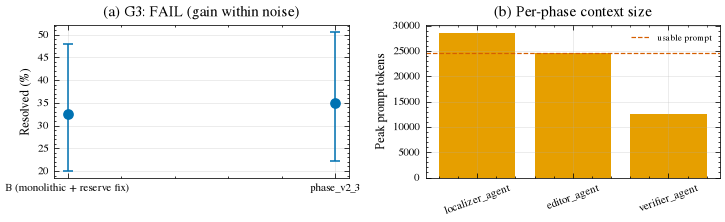

In [10]:
fig, (ax1, ax2) = plotting.figure("double", aspect=0.32, ncols=2)
s = summary.sort("arm")
labels = [P.baseline_label if a == "baseline" else P.variant for a in s["arm"]]
cis = [stats.wilson_ci(int(r["resolved"] * r["n"] + 0.5), r["n"]) for r in s.iter_rows(named=True)]
ax1.errorbar(
    labels,
    [c.point * 100 for c in cis],
    fmt="o",
    capsize=3,
    yerr=[[(c.point - c.lo) * 100 for c in cis], [(c.hi - c.point) * 100 for c in cis]],
)
ax1.set(ylabel="Resolved (%)", title=f"(a) G3: {g3['verdict']}")
ax2.bar(
    phase_calls["agent"].to_list(), phase_calls["peak_prompt"].to_list(), color=plotting.PALETTE[1]
)
ax2.axhline(32768 - 8192, ls="--", color=plotting.PALETTE[3], lw=0.8, label="usable prompt")
ax2.set(ylabel="Peak prompt tokens", title="(b) Per-phase context size")
ax2.tick_params(axis="x", labelrotation=20)
ax2.legend(fontsize=6)
fig.tight_layout()
plotting.save_fig(fig, f"e5_phase_agent_{P.variant}", exp_dir=EXP_DIR, run=run)

## 9 · Teardown

In [11]:
tables = EXP_DIR / "tables"
tables.mkdir(exist_ok=True)
summary.write_csv(tables / f"e5_{P.variant}_summary.csv")
phase_calls.write_csv(tables / f"e5_{P.variant}_phases.csv")
pl.DataFrame([g3]).write_csv(tables / f"e5_{P.variant}_g3.csv")
run.finish()
print((run.dir / "summary.json").read_text())

🏃 View run 20260926T194221Z-7cd18503-d596 at: http://127.0.0.1:5000/#/experiments/5/runs/4e66e9120bd34b019898938980639b8a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
{
  "run_id": "20260926T194221Z-7cd18503-d596",
  "status": "FINISHED",
  "wall_s": 6332.022,
  "monitor_overhead_s": {
    "gpu": 28.614,
    "host": 16.269,
    "containers": 21.408,
    "vllm": 56.702
  },
  "gpu_energy_kwh": 0.6188739358333334,
  "codecarbon": {
    "energy_kwh": 0.6751551464954523,
    "emissions_kg": 0.481683362870862,
    "cpu_kwh": 0.021146046496133334,
    "gpu_kwh": 0.6188527917485036,
    "ram_kwh": 0.035156308250815255,
    "region": "IND"
  }
}
